# E4.02.1 — Tuned acoustic SVM, frozen Whisper, and feature fusion

**Purpose: complete the missing matched A1 comparison.** Does acoustic information improve on a strong frozen Whisper-only classifier?

Use **Run All** with the **Singlish final fusion (Python 3.14)** kernel. This notebook is ready to run. No experiment results are included yet.

The notebook reuses the final 24 October data and the completed E2 Whisper controls. It does not extract Whisper features or train the Whisper controls again. “Tuned” means that validation data select SVM C. The Whisper encoder stays frozen.

| Model | Classifier inputs | Work in this notebook |
|---|---|---|
| Acoustic SVM65 | 65 selected acoustic features | Rank on training speakers, select C, and refit |
| Whisper full512 SVM | All 512 frozen Whisper features | Reuse completed E2 control |
| Whisper PCA32 SVM | 32 principal components of frozen Whisper features | Reuse completed E2 control |
| Fusion SVM65+32 | 65 acoustic features + 32 Whisper components | Use the new acoustic selection, select C, and refit |

**Primary comparison:** fusion minus full512 Whisper. This tests the value of the acoustic branch against the stronger Whisper control. Fusion minus acoustic SVM65 tests the gain over traditional acoustic machine learning. Fusion minus PCA32 Whisper is a supporting comparison.

## 1. Use the same data and selection rules

1. Verify all 40,000 clip identities, speaker groups, labels, splits, and audio hashes. Check both feature caches and the completed E2 files.
2. Fit a full91 acoustic SVM with C=1 on the original training speakers. Rank its 91 inputs by training-set permutation importance. Use five repeats and balanced accuracy. Retain the first 65 inputs. Keep these columns fixed for validation and the final refit.
3. Fit acoustic SVM65 and fusion separately for C = 0.01, 0.1, 1, and 10. Fit each scaler and PCA on training data only. Select the highest validation balanced accuracy. Break ties by macro F1, then smaller C.
4. Refit the selected pipelines on all development data. Keep the training-selected acoustic columns. Score the same 6,119 test clips as E2. Do not use test scores to change the models.
5. Compute paired 95% intervals with 2,000 whole-speaker bootstrap samples, stratified by class. Use the same sampled speakers for every model.

| Partition | Clips | Use |
|---|---:|---|
| Train | 27,797 | Acoustic ranking; fit each C candidate |
| Validation | 6,084 | Select C only |
| Development = train + validation | 33,881 | Refit selected classifiers, scalers, and PCA |
| Test | 6,119 | Compare fixed models |

Speaker groups do not cross partitions. Positive label 1 means Singaporean speech under the dataset label policy. Label 0 means non-Singaporean speech.

The 39-feature set is the earlier basic acoustic baseline. The 91-feature set adds first- and second-order MFCC differences. This notebook selects 65 from those 91 inputs. It does not repeat the 39-feature baseline or select the feature count again.

**Limits:** The test set has been inspected before. This is a retrospective comparison, not a new untouched test. The feature count, PCA width, branch weights, and model family are existing project choices. Training-set permutation importance can favour training patterns. Correlated inputs can share importance. The ranking is a selection rule, not a causal explanation. The intervals describe fixed fitted models; they exclude training and selection uncertainty. This notebook does not repeat the development speaker-fold study.

In [1]:
from pathlib import Path
from time import perf_counter
from datetime import datetime, timezone
from importlib.metadata import version
import hashlib
import importlib.util
import json
import platform
import tempfile

import joblib
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
import numpy as np
import pandas as pd
from IPython.display import display, Markdown
from sklearn.compose import ColumnTransformer
from sklearn.decomposition import PCA
from sklearn.inspection import permutation_importance
from sklearn.metrics import confusion_matrix, roc_auc_score
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC

ROOT = Path('/home/mh/nusproj/singlish-whisper')
NOTEBOOK = ROOT / 'notebooks/E4_02_1_tuned_acoustic_svm_whisper_and_fusion.ipynb'
DATA = ROOT / 'data/accent_dataset_3to6s_40k'
UPSTREAM = Path('/home/mh/nusproj/E1_Feature_EngineeringV4/outputs')
E1 = UPSTREAM / 'e1_feature_study_accent_40000'
E4 = UPSTREAM / 'svm65_fusion_comparison_40000'
E2 = ROOT / 'outputs/frozen_whisper_40000_20261028'
# A separate folder preserves the historical E1, E2, and E4 results.
OUT = ROOT / 'outputs/a1_tuned_acoustic_whisper_fusion_40000'

SEED = 42
C_VALUES = [0.01, 0.1, 1.0, 10.0]
FEATURE_COUNT = 65
PCA_WIDTH = 32
PERMUTATION_REPEATS = 5
BOOTSTRAP_REPEATS = 2000
ACOUSTIC = 'Acoustic SVM65'
FUSION = 'Fusion SVM65+32'
WHISPER = ['Whisper full512 SVM', 'Whisper PCA32 SVM']
NAMES = [ACOUSTIC, *WHISPER, FUSION]
NEW_MODELS = [ACOUSTIC, FUSION]
PACKAGES = {name: version(name) for name in
            ['numpy', 'pandas', 'scipy', 'scikit-learn', 'joblib',
             'matplotlib', 'pyarrow', 'soundfile']}

def sha256(path):
    result = hashlib.sha256()
    with Path(path).open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            result.update(block)
    return result.hexdigest()

HELPER = ROOT / 'notebooks/frozen_whisper_40k.py'
assert sha256(HELPER) == '2575187bf0e0e1c8cc1b0f285f2eba91ccefa8b329d7ac1f49d33c65e7b62d70', \
    'The completed E2 helper changed. Check the input provenance before continuing.'
spec = importlib.util.spec_from_file_location('a1_verified_e2_helper', HELPER)
fw = importlib.util.module_from_spec(spec)
spec.loader.exec_module(fw)

EXPECTED_E2_HASHES = {
    'run_metadata.json': '7cc0f7114c70786fdbc0b194c68af65c5572df7d5933b4d2a910b0f8f35c3a2a',
    'test_predictions.csv': '1aff74b323c42cc0439104911a8d929a11429d9f1af527827feb10311c87efc2',
    'validation_predictions.csv': '946277045484bb601a5b07cc4d7fb679393124246a6a5812521da9d77e4dcdf1',
    'validation_C_trials.csv': '6a694009f5da318c85943f94a8779f6498e123c3364ef01d7c6eda1f55dd785a',
    'selected_C.json': 'ced56dac7fd994361a282305fe93c165575985bd4bc9a8ea81939ce541e5a004',
    'timing.csv': 'cdaedcb063585c892e5834ccf17b1b99c44530b099fb26e8548fccdee6ccdbdb',
    'test_metrics.json': 'a074dd89a695164de2b112f43bc1a873ec19d34f7b980f4a2397f3777eda97eb',
    'whisper_full512_svm.joblib': '6e05966265094626349ed6ec2267bf515e333da4fc47d3b539e8f38fa8be4d08',
    'whisper_pca32_svm.joblib': 'e6cd74aabcd6162d40f011b20d2cdc7717c7f375f931d32bffa34175b0e2611b',
}

print('Python:', platform.python_version(), '| scikit-learn:', PACKAGES['scikit-learn'])
print('Output:', OUT)
print('No package installation, Whisper extraction, or Whisper head training is required.')

Python: 3.14.7 | scikit-learn: 1.9.1
Output: /home/mh/nusproj/singlish-whisper/outputs/a1_tuned_acoustic_whisper_fusion_40000
No package installation, Whisper extraction, or Whisper head training is required.


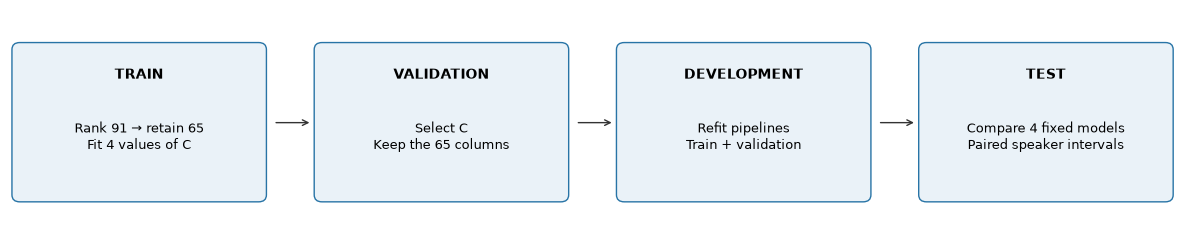

In [2]:
fig, ax = plt.subplots(figsize=(12, 2.5))
ax.set(xlim=(0, 12), ylim=(0, 2.5))
ax.axis('off')
boxes = [
    (0.1, 'TRAIN', 'Rank 91 → retain 65\nFit 4 values of C'),
    (3.2, 'VALIDATION', 'Select C\nKeep the 65 columns'),
    (6.3, 'DEVELOPMENT', 'Refit pipelines\nTrain + validation'),
    (9.4, 'TEST', 'Compare 4 fixed models\nPaired speaker intervals'),
]
for x, title, detail in boxes:
    ax.add_patch(FancyBboxPatch((x, 0.4), 2.45, 1.65,
                               boxstyle='round,pad=0.08', fc='#eaf2f8', ec='#2874a6'))
    ax.text(x + 1.225, 1.72, title, ha='center', weight='bold', fontsize=10)
    ax.text(x + 1.225, 1.06, detail, ha='center', va='center', fontsize=9)
    if x < 9:
        ax.annotate('', xy=(x+3.0, 1.22), xytext=(x+2.6, 1.22),
                    arrowprops={'arrowstyle': '->', 'color': '#333333'})
fig.tight_layout()
plt.show()
plt.close(fig)

## 2. Define the models and checks

Acoustic SVM65 uses a standard scaler and an RBF SVM. Fusion uses two branches:

- Acoustic branch: standard scaler, then divide by √65.
- Whisper branch: standard scaler → PCA32 → standard scaler, then divide by √32.

Concatenate the branches to form 97 processed inputs. Fit one RBF SVM. The branch weights match the original fusion method. Each C candidate uses `gamma='scale'` and `class_weight='balanced'`. There is no probability calibration. A decision score is not a probability.

In [3]:
def make_model(name, c):
    classifier = SVC(C=float(c), kernel='rbf', gamma='scale',
                     class_weight='balanced', random_state=SEED, cache_size=2048)
    if name == ACOUSTIC:
        return Pipeline([('scale', StandardScaler()), ('classifier', classifier)])
    if name != FUSION:
        raise ValueError(name)
    whisper_branch = Pipeline([
        ('scale', StandardScaler()),
        ('pca', PCA(n_components=PCA_WIDTH, random_state=SEED)),
        ('component_scale', StandardScaler()),
    ])
    preprocess = ColumnTransformer([
        ('acoustic', StandardScaler(), list(range(FEATURE_COUNT))),
        ('whisper', whisper_branch, list(range(FEATURE_COUNT, FEATURE_COUNT+512))),
    ], transformer_weights={'acoustic': 1/np.sqrt(FEATURE_COUNT),
                             'whisper': 1/np.sqrt(PCA_WIDTH)})
    return Pipeline([('preprocess', preprocess), ('classifier', classifier)])


def check_fit_scope(model, name, values):
    # Check both sample counts and means. PCA must use the same fitting rows.
    if name == ACOUSTIC:
        scaler = model.named_steps['scale']
        assert scaler.n_samples_seen_ == len(values)
        np.testing.assert_allclose(scaler.mean_, values.mean(0, dtype=np.float64), atol=1e-9)
    else:
        pre = model.named_steps['preprocess']
        acoustic = pre.named_transformers_['acoustic']
        whisper = pre.named_transformers_['whisper']
        assert acoustic.n_samples_seen_ == len(values)
        assert whisper['scale'].n_samples_seen_ == len(values)
        assert whisper['component_scale'].n_samples_seen_ == len(values)
        assert whisper['pca'].n_samples_ == len(values)
        np.testing.assert_allclose(acoustic.mean_, values[:, :FEATURE_COUNT].mean(0, dtype=np.float64), atol=1e-9)
        np.testing.assert_allclose(whisper['scale'].mean_, values[:, FEATURE_COUNT:].mean(0, dtype=np.float64), atol=1e-9)
        assert pre.transform(values[:2]).shape == (2, FEATURE_COUNT+PCA_WIDTH)


PRED_COLUMNS = ['clip_id', 'speaker_group', 'source', 'accent_group', 'label',
                'model', 'stage', 'prediction', 'decision_score']


def check_predictions(predictions, expected, name, stage):
    assert len(predictions) == len(expected) and predictions.clip_id.is_unique
    part = predictions.set_index('clip_id').sort_index()
    truth = expected.set_index('clip_id').sort_index()
    pd.testing.assert_frame_equal(part[['speaker_group', 'source', 'accent_group', 'label']],
                                  truth[['speaker_group', 'source', 'accent_group', 'label']],
                                  check_dtype=False)
    assert predictions.model.eq(name).all() and predictions.stage.eq(stage).all()
    assert set(predictions.prediction) <= {0, 1}
    assert np.isfinite(predictions.decision_score).all()


def score_predictions(model, values, expected, name, stage):
    part = expected[['clip_id', 'speaker_group', 'source', 'accent_group', 'label']].copy()
    part['model'], part['stage'] = name, stage
    part['prediction'] = model.predict(values)
    part['decision_score'] = model.decision_function(values)
    part = part[PRED_COLUMNS].reset_index(drop=True)
    check_predictions(part, expected, name, stage)
    return part


def choose_trial(trials):
    return max(trials, key=lambda row: (row['balanced_accuracy'], row['macro_f1'], -row['C']))


def save_checkpoint(state):
    temporary = OUT / 'study.joblib.tmp'
    joblib.dump(state, temporary, compress=3)
    temporary.replace(OUT / 'study.joblib')


def paired_bootstrap(predictions, names, repeats=BOOTSTRAP_REPEATS, seed=SEED):
    # Aggregate confusion counts by speaker. Reuse each draw across all models.
    parts = {name: predictions.loc[predictions.model.eq(name)].set_index('clip_id').sort_index()
             for name in names}
    reference = parts[names[0]][['speaker_group', 'label']]
    assert reference.index.is_unique
    assert reference.groupby('speaker_group').label.nunique().eq(1).all()
    for part in parts.values():
        pd.testing.assert_frame_equal(part[['speaker_group', 'label']], reference)
    speakers = reference.groupby('speaker_group').label.first().sort_index()
    group_positions = speakers.index.get_indexer(reference.speaker_group)
    rng = np.random.default_rng(seed)
    weights = np.zeros((repeats, len(speakers)), dtype=np.int32)
    for label in [0, 1]:
        ids = np.flatnonzero(speakers.eq(label))
        assert len(ids) > 1, 'Each class needs at least two speakers.'
        draws = ids[rng.integers(len(ids), size=(repeats, len(ids)))]
        np.add.at(weights, (np.arange(repeats)[:, None], draws), 1)

    def from_cm(cm):
        tn, fp, fn, tp = np.asarray(cm).T
        return {'balanced_accuracy': .5*(tp/(tp+fn) + tn/(tn+fp)),
                'macro_f1': .5*(2*tp/(2*tp+fp+fn) + 2*tn/(2*tn+fp+fn))}

    samples, scores, rows = {}, {}, []
    for name, part in parts.items():
        cm = np.zeros((len(speakers), 4), dtype=np.int64)
        np.add.at(cm, (group_positions, 2*part.label.to_numpy()+part.prediction.to_numpy()), 1)
        samples[name] = from_cm(weights @ cm)
        result = fw.metrics(part)
        result['speaker_ci95'] = {metric: np.quantile(draws, [.025, .975]).tolist()
                                   for metric, draws in samples[name].items()}
        scores[name] = result
        rows.append(dict(model=name, **{k: v for k, v in result.items()
                                       if k not in ['confusion_matrix', 'speaker_ci95']},
                         ba_ci95_low=result['speaker_ci95']['balanced_accuracy'][0],
                         ba_ci95_high=result['speaker_ci95']['balanced_accuracy'][1],
                         f1_ci95_low=result['speaker_ci95']['macro_f1'][0],
                         f1_ci95_high=result['speaker_ci95']['macro_f1'][1]))
    comparisons = []
    for control in [WHISPER[0], ACOUSTIC, WHISPER[1]]:
        candidate = parts[FUSION]
        correct_c = candidate.prediction.eq(candidate.label)
        correct_r = parts[control].prediction.eq(candidate.label)
        for metric in ['balanced_accuracy', 'macro_f1']:
            delta = samples[FUSION][metric]-samples[control][metric]
            low, high = np.quantile(delta, [.025, .975])
            comparisons.append(dict(candidate=FUSION, reference=control, metric=metric,
                difference=scores[FUSION][metric]-scores[control][metric],
                ci95_low=float(low), ci95_high=float(high),
                fusion_only_correct=int((correct_c & ~correct_r).sum()),
                reference_only_correct=int((~correct_c & correct_r).sum())))
    return pd.DataFrame(rows), scores, pd.DataFrame(comparisons)


def source_table(predictions):
    rows = []
    for (name, source), part in predictions.groupby(['model', 'source'], sort=False):
        assert part.label.nunique() == 1, 'Expected one class per source in this dataset.'
        label = int(part.label.iloc[0])
        rows.append(dict(model=name, source=source, label=label, clips=len(part),
                         speakers=part.speaker_group.nunique(),
                         errors=int(part.label.ne(part.prediction).sum()),
                         metric='Singapore recall' if label else 'non-Singapore specificity',
                         value=float(part.label.eq(part.prediction).mean())))
    return pd.DataFrame(rows)


def markdown_table(table):
    # Avoid an optional tabulate dependency.
    clean = table.fillna('').astype(str).map(lambda value: value.replace('|', '/').replace('\n', ' '))
    lines = ['| ' + ' | '.join(map(str, clean.columns)) + ' |',
             '| ' + ' | '.join(['---'] * len(clean.columns)) + ' |']
    lines += ['| ' + ' | '.join(row) + ' |' for row in clean.itertuples(index=False, name=None)]
    return '\n'.join(lines)


def describe_difference(row):
    value, low, high = 100*row.difference, 100*row.ci95_low, 100*row.ci95_high
    prefix = f'Fusion minus {row.reference}: {value:+.3f} percentage points; 95% interval [{low:+.3f}, {high:+.3f}]. '
    if low > 0:
        return prefix + 'The interval supports a fusion gain on this retrospective test.'
    if high < 0:
        return prefix + 'The interval supports a lower fusion score on this retrospective test.'
    return prefix + 'The interval includes zero. A fusion gain is not established. This does not establish equivalence.'

## 3. Verify the inputs

This cell reads the prepared Parquet data. It decodes every clip to check the audio hash. It then checks the acoustic91 cache and the frozen Whisper cache. It uses the unchanged E2 audit functions.

The audit does not trim, resample, normalize, or encode the audio again. Temporary audit files are removed after the checks. The final run record stores the audit summary and input hashes. A mismatch stops the run. Check the named file; do not remove a check to force the run to continue.

In [4]:
input_started = perf_counter()
for filename, expected_hash in EXPECTED_E2_HASHES.items():
    assert sha256(E2 / filename) == expected_hash, f'E2 file changed: {filename}'
assert sha256(E1 / 'speaker_splits.csv') == '428937b39eb646a41e46b8ee3cdeb86652069802a675575892e6f17e289b8581'
acoustic_path = E1 / 'acoustic_features_91.npz'
acoustic_sha = sha256(acoustic_path)
assert acoustic_sha == '5bd24a1f3a26b05a02694ed4a1d4e3fc0b72524eaea45d1429276f0f71f2438d'

with tempfile.TemporaryDirectory(prefix='singlish_a1_audit_') as scratch:
    cfg = dict(root=ROOT, data=DATA, output=Path(scratch), e1=E1, fusion=E4,
               reference=Path('/home/mh/nusproj/Singlish/accent_classifier_data/manifests/clips_40000.csv.gz'),
               workers=8, rebuild_whisper=False)
    frame, split, split_summary = fw.load_dataset(cfg)
    audio_audit = fw.audit_audio(cfg, frame)
    assert audio_audit['encoded_hash_matches_original_cache'] == 40000
    W, whisper_provenance = fw.load_whisper(cfg, frame)
    dataset_identity = json.loads((Path(scratch) / 'dataset_identity.json').read_text())

assert whisper_provenance['cache_file_sha256'] == 'bccf31584fd0af0d2b248ef8182cef4145894e93b965e2e60f734ed859d071cb'
with np.load(acoustic_path, allow_pickle=False) as cache:
    for key, expected in [('clip_ids', frame.clip_id), ('labels', frame.label),
                          ('groups', frame.speaker_group)]:
        assert np.array_equal(cache[key], expected), f'Acoustic identity mismatch: {key}'
    assert cache['cache_id'].item() == '79ab75a64cb2c58cbc8a4a0a412aa8bd6d43e5dff1fbbf4c4f1c5508c606961e'
    X91, feature_names = cache['features'].copy(), cache['feature_names'].copy()
assert X91.shape == (40000, 91) and np.isfinite(X91).all()
assert len(set(feature_names)) == 91
assert W.shape == (40000, 512) and np.isfinite(W).all()

e2_record = json.loads((E2 / 'run_metadata.json').read_text())
assert e2_record['dataset_id'] == fw.DATASET_ID
assert e2_record['whisper_provenance']['cache_file_sha256'] == whisper_provenance['cache_file_sha256']
assert e2_record['helper_sha256'] == sha256(HELPER)
assert e2_record['seed'] == SEED and not e2_record['calibrated_probability_comparison']
e2_c = json.loads((E2 / 'selected_C.json').read_text())
e2_trials = pd.read_csv(E2 / 'validation_C_trials.csv')
assert set(e2_trials.model) == set(WHISPER)
for name in WHISPER:
    part = e2_trials.loc[e2_trials.model.eq(name)]
    assert len(part) == len(C_VALUES) and sorted(part.C.tolist()) == C_VALUES
    assert choose_trial(part.to_dict('records'))['C'] == e2_c[name] == e2_record['selected_C'][name]

e2_predictions = {}
for stage in ['validation', 'test']:
    imported = pd.read_csv(E2 / f'{stage}_predictions.csv')
    kept = []
    for name in WHISPER:
        part = imported.loc[imported.model.eq(name), PRED_COLUMNS].copy()
        check_predictions(part, frame.iloc[split[stage]], name, stage)
        kept.append(part)
    e2_predictions[stage] = pd.concat(kept, ignore_index=True)
e2_metrics = json.loads((E2 / 'test_metrics.json').read_text())
for name in WHISPER:
    computed = fw.metrics(e2_predictions['test'].query('model == @name'))
    for key in ['balanced_accuracy', 'macro_f1', 'roc_auc', 'errors', 'false_positive', 'false_negative']:
        assert np.isclose(computed[key], e2_metrics[name][key], atol=1e-12, rtol=0), (name, key)

input_hashes = {str(E2 / filename): value for filename, value in EXPECTED_E2_HASHES.items()}
input_hashes.update({str(HELPER): sha256(HELPER), str(acoustic_path): acoustic_sha,
                     str(E1 / 'speaker_splits.csv'): dataset_identity['original_split_sha256'],
                     str(E1 / 'current_cache_metadata.json'): sha256(E1 / 'current_cache_metadata.json'),
                     str(E4 / 'model_metadata.json'): sha256(E4 / 'model_metadata.json'),
                     whisper_provenance['cache_path']: whisper_provenance['cache_file_sha256']})
input_seconds = perf_counter()-input_started
display(split_summary)
print('All input checks passed. Completed Whisper controls imported; no Whisper fitting was done.')

Metadata matches the final fusion data. Speaker overlap: 0.
Audio audit: 250/40,000 decoded
Audio audit: 500/40,000 decoded
Audio audit: 750/40,000 decoded
Audio audit: 1,000/40,000 decoded
Audio audit: 1,250/40,000 decoded
Audio audit: 1,500/40,000 decoded
Audio audit: 1,750/40,000 decoded
Audio audit: 2,000/40,000 decoded
Audio audit: 2,250/40,000 decoded
Audio audit: 2,500/40,000 decoded
Audio audit: 2,750/40,000 decoded
Audio audit: 3,000/40,000 decoded
Audio audit: 3,250/40,000 decoded
Audio audit: 3,500/40,000 decoded
Audio audit: 3,750/40,000 decoded
Audio audit: 4,000/40,000 decoded
Audio audit: 4,250/40,000 decoded
Audio audit: 4,500/40,000 decoded
Audio audit: 4,750/40,000 decoded
Audio audit: 5,000/40,000 decoded
Audio audit: 5,250/40,000 decoded
Audio audit: 5,500/40,000 decoded
Audio audit: 5,750/40,000 decoded
Audio audit: 6,000/40,000 decoded
Audio audit: 6,250/40,000 decoded
Audio audit: 6,500/40,000 decoded
Audio audit: 6,750/40,000 decoded
Audio audit: 7,000/40,000 de

,split,label,clips,speakers
0,test,0,3085,1267
1,test,1,3034,215
2,train,0,13848,5960
3,train,1,13949,979
4,validation,0,3067,1300
5,validation,1,3017,204


All input checks passed. Completed Whisper controls imported; no Whisper fitting was done.


## 4. Start or resume this study

The notebook saves one checkpoint file after the feature ranking, each C trial, and each final model. If the kernel stops, use **Restart Kernel and Run All**. Completed stages are reused only when the code, settings, package versions, and input hashes match.

The full91 permutation ranking is usually the slowest step. It makes five shuffled predictions for each of 91 inputs on all training clips. It uses the CPU and one worker. If this cell is interrupted before ranking completes, that ranking must start again. Later fitting stages resume from their last completed checkpoint.

To run a changed experiment, set `OUT` to a new folder and save the notebook first. Keep the historical output folder for comparison.

In [5]:
notebook_content = json.loads(NOTEBOOK.read_text())
code_sha = hashlib.sha256('\n\n'.join(''.join(cell['source']) for cell in notebook_content['cells']
                                      if cell['cell_type'] == 'code').encode()).hexdigest()
settings = dict(seed=SEED, C_values=C_VALUES, acoustic_count=FEATURE_COUNT,
                ranking_C=1.0, permutation_repeats=PERMUTATION_REPEATS,
                ranking_rows='original training only', ranking_scoring='balanced_accuracy',
                PCA_width=PCA_WIDTH, branch_weights='1/sqrt(branch width)',
                kernel='rbf', gamma='scale', class_weight='balanced',
                calibration=False, bootstrap_repeats=BOOTSTRAP_REPEATS,
                tie_break='validation BA, macro F1, smaller C',
                final_columns='keep training-selected 65 fixed',
                python=platform.python_version())
signature = fw.digest(dict(code_sha256=code_sha, settings=settings,
                           packages=PACKAGES, inputs=input_hashes))
OUT.mkdir(parents=True, exist_ok=True)
if (OUT / 'study.joblib').exists():
    state = joblib.load(OUT / 'study.joblib')
    assert state['signature'] == signature, 'Checkpoint differs. Use a new OUT folder for changed inputs or code.'
    print('Matching checkpoint loaded.')
else:
    assert not any(OUT.iterdir()), 'Output folder is not empty and has no checkpoint. Use a new folder.'
    state = dict(signature=signature, started_utc=datetime.now(timezone.utc).isoformat(),
                 ranking=None, trials={}, final={})
    save_checkpoint(state)
record = dict(status='in_progress', started_utc=state['started_utc'], signature=signature,
              code_sha256=code_sha, settings=settings, packages=PACKAGES,
              dataset=dataset_identity, audio_audit=audio_audit,
              whisper=whisper_provenance, input_hashes=input_hashes,
              input_check_seconds=input_seconds,
              retrospective=True, speaker_folds_repeated=False)
fw.write_json(OUT / 'run_record.json', record)

## 5. Rank acoustic inputs on training speakers only

The ranking model uses all 91 acoustic inputs. The importance value is the loss of training balanced accuracy when one input is shuffled. The five-repeat standard deviation describes variation between shuffles. It is not a confidence interval.

Sort by mean importance, then feature name to break ties. Keep 65 columns. Do not use the old development-ranked columns from `svm_65.joblib`.

Fit the full91 training-only ranking model, then compute 91 × 5 permutations.


,rank,column_in_91,feature,importance_mean,shuffle_std,selected
0,1,14,mfcc_2_std,0.013766,0.000517,True
1,2,35,zcr_mean,0.012971,0.000485,True
2,3,31,spectral_bandwidth_mean,0.008905,0.000421,True
3,4,5,mfcc_6_mean,0.008005,0.000366,True
4,5,78,mfcc_delta_delta_1_std,0.007815,0.000783,True
...,...,...,...,...,...,...
86,87,64,mfcc_delta_13_std,0.000185,0.000176,False
87,88,90,mfcc_delta_delta_13_std,0.000176,0.000244,False
88,89,86,mfcc_delta_delta_9_std,0.000099,0.000070,False
89,90,62,mfcc_delta_11_std,0.000099,0.000227,False


Retain 65/91 acoustic inputs: 28.6% fewer.
Ranking seconds: 4598.6


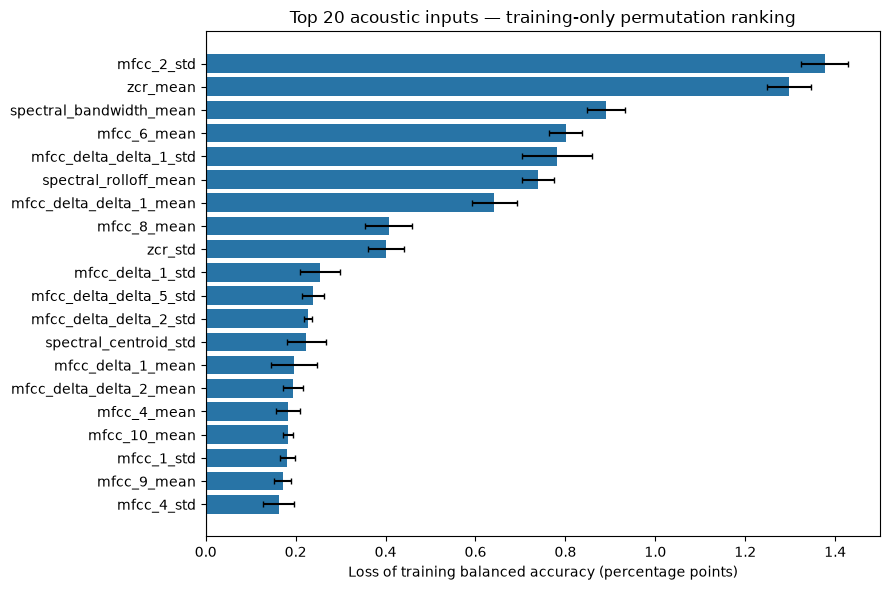

In [6]:
train, val, dev, test = [split[key] for key in ['train', 'validation', 'development', 'test']]
y = frame.label.to_numpy()
if state['ranking'] is None:
    print('Fit the full91 training-only ranking model, then compute 91 × 5 permutations.', flush=True)
    started = perf_counter()
    ranking_model = Pipeline([
        ('scale', StandardScaler()),
        ('classifier', SVC(C=1.0, kernel='rbf', gamma='scale', class_weight='balanced',
                           random_state=SEED, cache_size=2048)),
    ]).fit(X91[train], y[train])
    rank_fit_seconds = perf_counter()-started
    check_fit_scope(ranking_model, ACOUSTIC, X91[train])
    started = perf_counter()
    importance = permutation_importance(ranking_model, X91[train], y[train],
        scoring='balanced_accuracy', n_repeats=PERMUTATION_REPEATS,
        random_state=SEED, n_jobs=1)
    order = np.asarray(sorted(range(91), key=lambda i: (-float(importance.importances_mean[i]),
                                                       str(feature_names[i]))), dtype=int)
    state['ranking'] = dict(order=order, mean=importance.importances_mean,
                            std=importance.importances_std, repeats=importance.importances,
                            fit_seconds=rank_fit_seconds, permutation_seconds=perf_counter()-started,
                            fitting_clips=len(train), fitting_speakers=frame.iloc[train].speaker_group.nunique())
    save_checkpoint(state)
else:
    print('Reuse the completed training-only ranking from this matching study.')
selected_columns = state['ranking']['order'][:FEATURE_COUNT]
assert len(set(selected_columns)) == FEATURE_COUNT
ranking_table = pd.DataFrame({'rank': np.arange(1, 92),
                              'column_in_91': state['ranking']['order'],
                              'feature': feature_names[state['ranking']['order']],
                              'importance_mean': state['ranking']['mean'][state['ranking']['order']],
                              'shuffle_std': state['ranking']['std'][state['ranking']['order']]})
ranking_table['selected'] = ranking_table['rank'].le(FEATURE_COUNT)
state['feature_names_91'] = feature_names.tolist()
state['selected_columns'] = selected_columns.tolist()
state['selected_feature_names'] = feature_names[selected_columns].tolist()
save_checkpoint(state)
A = X91[:, selected_columns]
inputs = {ACOUSTIC: A, FUSION: np.column_stack([A, W])}
display(ranking_table)
print(f'Retain {FEATURE_COUNT}/91 acoustic inputs: {100*(91-FEATURE_COUNT)/91:.1f}% fewer.')
print('Ranking seconds:', round(state['ranking']['fit_seconds']+state['ranking']['permutation_seconds'], 1))

top = ranking_table.head(20).iloc[::-1]
fig, ax = plt.subplots(figsize=(9, 6))
ax.barh(top.feature, 100*top.importance_mean, xerr=100*top.shuffle_std, color='#2874a6', capsize=2)
ax.set(xlabel='Loss of training balanced accuracy (percentage points)',
       title='Top 20 acoustic inputs — training-only permutation ranking')
ax.axvline(0, color='#555555', linewidth=.8)
fig.tight_layout()
plt.show()
plt.close(fig)

## 6. Select SVM C with validation speakers

Both new models use the same four C values as the completed Whisper controls. The 65 acoustic columns stay fixed. Every scaler and PCA is fitted within the training pipeline. This cell does not read test predictions to select C.

Fit: Acoustic SVM65|C=0.01
Validation BA: 92.4943%; macro F1: 0.9249
Fit: Acoustic SVM65|C=0.1
Validation BA: 95.4409%; macro F1: 0.9543
Fit: Acoustic SVM65|C=1
Validation BA: 97.1170%; macro F1: 0.9711
Fit: Acoustic SVM65|C=10
Validation BA: 97.1113%; macro F1: 0.9711
Fit: Fusion SVM65+32|C=0.01
Validation BA: 95.3577%; macro F1: 0.9535
Fit: Fusion SVM65+32|C=0.1
Validation BA: 97.7742%; macro F1: 0.9776
Fit: Fusion SVM65+32|C=1
Validation BA: 98.6572%; macro F1: 0.9865
Fit: Fusion SVM65+32|C=10
Validation BA: 98.7225%; macro F1: 0.9872


,model,C,balanced_accuracy,macro_f1,selected,origin
0,Acoustic SVM65,0.01,0.924943,0.924885,False,new training-only acoustic selection
1,Acoustic SVM65,0.10,0.954409,0.954305,False,new training-only acoustic selection
2,Acoustic SVM65,1.00,0.971170,0.971071,True,new training-only acoustic selection
3,Acoustic SVM65,10.00,0.971113,0.971071,False,new training-only acoustic selection
4,Fusion SVM65+32,0.01,0.953577,0.953484,False,new training-only acoustic selection
5,Fusion SVM65+32,0.10,0.977742,0.977646,False,new training-only acoustic selection
6,Fusion SVM65+32,1.00,0.986572,0.986522,False,new training-only acoustic selection
7,Fusion SVM65+32,10.00,0.987225,0.987179,True,new training-only acoustic selection
8,Whisper full512 SVM,0.01,0.936042,0.935891,False,completed E2 control
9,Whisper full512 SVM,0.10,0.972151,0.972058,False,completed E2 control


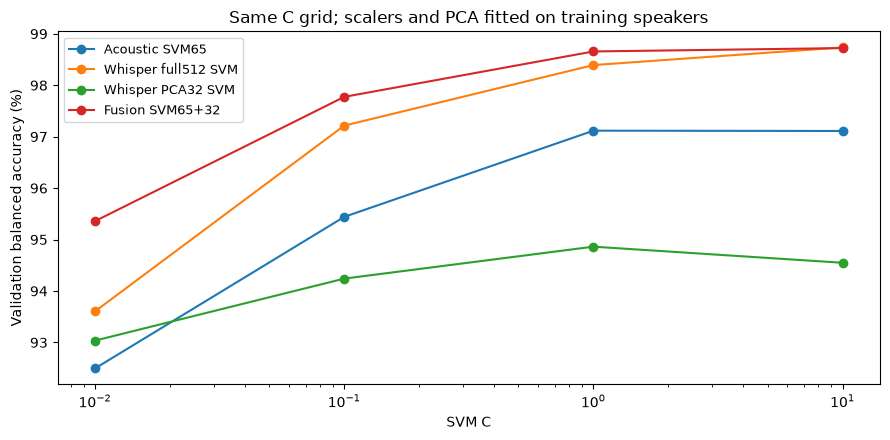

In [7]:
for name in NEW_MODELS:
    for c in C_VALUES:
        key = f'{name}|C={c:g}'
        if key in state['trials']:
            print('Reuse completed trial:', key)
            continue
        print('Fit:', key, flush=True)
        started = perf_counter()
        model = make_model(name, c).fit(inputs[name][train], y[train])
        fit_seconds = perf_counter()-started
        check_fit_scope(model, name, inputs[name][train])
        started = perf_counter()
        pred = score_predictions(model, inputs[name][val], frame.iloc[val], name, 'validation')
        row = dict(model=name, C=c, fit_seconds=fit_seconds,
                   validation_predict_and_score_seconds=perf_counter()-started,
                   **fw.flat_metrics(pred), origin='new training-only acoustic selection')
        state['trials'][key] = dict(row=row, predictions=pred)
        save_checkpoint(state)
        print(f'Validation BA: {row["balanced_accuracy"]:.4%}; macro F1: {row["macro_f1"]:.4f}', flush=True)

new_trials = pd.DataFrame([value['row'] for value in state['trials'].values()])
selected_c = dict(e2_c)
validation_parts = [e2_predictions['validation']]
for name in NEW_MODELS:
    best = choose_trial(new_trials.loc[new_trials.model.eq(name)].to_dict('records'))
    selected_c[name] = best['C']
    validation_parts.append(state['trials'][f'{name}|C={best["C"]:g}']['predictions'])
validation_predictions = pd.concat(validation_parts, ignore_index=True)
validation_trials = pd.concat([new_trials, e2_trials.assign(origin='completed E2 control')], ignore_index=True)
validation_trials['selected'] = [c == selected_c[name]
                                 for name, c in zip(validation_trials.model, validation_trials.C)]
validation_trials.to_csv(OUT / 'validation_trials.csv', index=False)
state['selected_C'] = selected_c
save_checkpoint(state)
display(validation_trials[['model', 'C', 'balanced_accuracy', 'macro_f1', 'selected', 'origin']])

fig, ax = plt.subplots(figsize=(9, 4.5))
for name in NAMES:
    part = validation_trials.loc[validation_trials.model.eq(name)].sort_values('C')
    ax.plot(part.C, 100*part.balanced_accuracy, 'o-', label=name)
ax.set(xscale='log', xlabel='SVM C', ylabel='Validation balanced accuracy (%)',
       title='Same C grid; scalers and PCA fitted on training speakers')
ax.legend(fontsize=9)
fig.tight_layout()
plt.show()
plt.close(fig)

## 7. Refit on development data and score the fixed test clips

The selected C and 65 column identities are now fixed. Fit the two new pipelines on all 33,881 development clips. Refit scaling and PCA as part of each pipeline. Reuse the two completed Whisper test predictions.

The saved pipelines expect **raw cached inputs**: acoustic SVM65 expects the selected 65 columns in saved order; fusion expects those 65 columns followed by all 512 raw Whisper values. The saved pipeline does scaling and PCA. The checkpoint also stores column names and indices.

In [8]:
for name in NEW_MODELS:
    if name in state['final']:
        print('Reuse completed development refit and test predictions:', name)
        continue
    print('Development refit:', name, flush=True)
    started = perf_counter()
    model = make_model(name, selected_c[name]).fit(inputs[name][dev], y[dev])
    fit_seconds = perf_counter()-started
    check_fit_scope(model, name, inputs[name][dev])
    started = perf_counter()
    pred = score_predictions(model, inputs[name][test], frame.iloc[test], name, 'test')
    state['final'][name] = dict(model=model, predictions=pred,
        timing=dict(model=name, final_fit_seconds=fit_seconds,
                    test_predict_and_score_seconds=perf_counter()-started,
                    origin='current run; cached input features'))
    save_checkpoint(state)

test_predictions = pd.concat([e2_predictions['test']]+
                              [state['final'][name]['predictions'] for name in NEW_MODELS], ignore_index=True)
for name in NAMES:
    check_predictions(test_predictions.loc[test_predictions.model.eq(name)], frame.iloc[test], name, 'test')
    check_predictions(validation_predictions.loc[validation_predictions.model.eq(name)], frame.iloc[val], name, 'validation')
all_predictions = pd.concat([validation_predictions, test_predictions], ignore_index=True)
assert len(all_predictions) == 4*(len(val)+len(test))
all_predictions.to_csv(OUT / 'predictions.csv', index=False)
timing = pd.concat([
    pd.DataFrame([state['final'][name]['timing'] for name in NEW_MODELS]),
    pd.read_csv(E2 / 'timing.csv').assign(origin='completed E2 run; cached input features'),
], ignore_index=True)
display(timing)
print('Times include fitting and test predict + decision score calls. They exclude feature extraction.')
print('E2 and current-run times were measured in separate runs. They are descriptive, not an end-to-end benchmark.')

Development refit: Acoustic SVM65
Development refit: Fusion SVM65+32


,model,final_fit_seconds,test_predict_and_score_seconds,origin
0,Acoustic SVM65,14.067511,3.541095,current run; cached input features
1,Fusion SVM65+32,14.660307,3.360500,current run; cached input features
2,Whisper full512 SVM,50.497807,27.010955,completed E2 run; cached input features
3,Whisper PCA32 SVM,11.326246,2.914208,completed E2 run; cached input features


Times include fitting and test predict + decision score calls. They exclude feature extraction.
E2 and current-run times were measured in separate runs. They are descriptive, not an end-to-end benchmark.


## 8. Measure performance and paired uncertainty

Balanced accuracy is the mean of Singapore recall and non-Singapore specificity. Macro F1 gives equal weight to the two class F1 scores. ROC AUC uses the raw SVM decision score. FP means a non-Singapore clip classified as Singapore. FN means a Singapore clip classified as non-Singapore.

The bootstrap resamples whole speakers within each class. It retains every clip from a sampled speaker. This preserves the dependence between clips from the same speaker. Scores remain clip-based; the bootstrap does not give each speaker equal weight in the score.

The primary interval is fusion minus full512 Whisper. Secondary comparisons are descriptive. No multiple-comparison correction is applied. An interval that includes zero does not establish a gain or equivalence.

,model,C,balanced_accuracy,ba_ci95_low,ba_ci95_high,macro_f1,roc_auc,false_positive,false_negative,errors
0,Acoustic SVM65,1.0,0.965650,0.957104,0.973264,0.965515,0.994539,155,56,211
1,Whisper full512 SVM,10.0,0.987268,0.982524,0.991576,0.987252,0.999089,45,33,78
2,Whisper PCA32 SVM,1.0,0.954260,0.943014,0.964188,0.954239,0.989560,148,132,280
3,Fusion SVM65+32,10.0,0.986820,0.982189,0.990805,0.986763,0.999086,62,19,81


,reference,metric,difference_pp,low_pp,high_pp,fusion_only_correct,reference_only_correct
0,Whisper full512 SVM,balanced_accuracy,-0.044808,-0.490382,0.411856,58,61
1,Whisper full512 SVM,macro_f1,-0.048978,-0.500153,0.403940,58,61
2,Acoustic SVM65,balanced_accuracy,2.117049,1.538039,2.726610,157,27
3,Acoustic SVM65,macro_f1,2.124740,1.539835,2.762867,157,27
4,Whisper PCA32 SVM,balanced_accuracy,3.256069,2.348529,4.328175,240,41
5,Whisper PCA32 SVM,macro_f1,3.252313,2.330009,4.331124,240,41


,model,source,label,clips,speakers,errors,metric,value
0,Whisper full512 SVM,common_voice,0,2913,1241,25,non-Singapore specificity,0.991418
1,Whisper full512 SVM,mnsc,1,3034,215,33,Singapore recall,0.989123
2,Whisper full512 SVM,speech_accent_archive,0,50,8,1,non-Singapore specificity,0.980000
3,Whisper full512 SVM,speechocean762,0,122,18,19,non-Singapore specificity,0.844262
4,Whisper PCA32 SVM,common_voice,0,2913,1241,96,non-Singapore specificity,0.967044
5,Whisper PCA32 SVM,mnsc,1,3034,215,132,Singapore recall,0.956493
6,Whisper PCA32 SVM,speech_accent_archive,0,50,8,3,non-Singapore specificity,0.940000
7,Whisper PCA32 SVM,speechocean762,0,122,18,49,non-Singapore specificity,0.598361
8,Acoustic SVM65,common_voice,0,2913,1241,83,non-Singapore specificity,0.971507
9,Acoustic SVM65,mnsc,1,3034,215,56,Singapore recall,0.981543


Fusion minus Whisper full512 SVM: -0.045 percentage points; 95% interval [-0.490, +0.412]. The interval includes zero. A fusion gain is not established. This does not establish equivalence.
Fusion minus Acoustic SVM65: +2.117 percentage points; 95% interval [+1.538, +2.727]. The interval supports a fusion gain on this retrospective test.
Fusion minus Whisper PCA32 SVM: +3.256 percentage points; 95% interval [+2.349, +4.328]. The interval supports a fusion gain on this retrospective test.


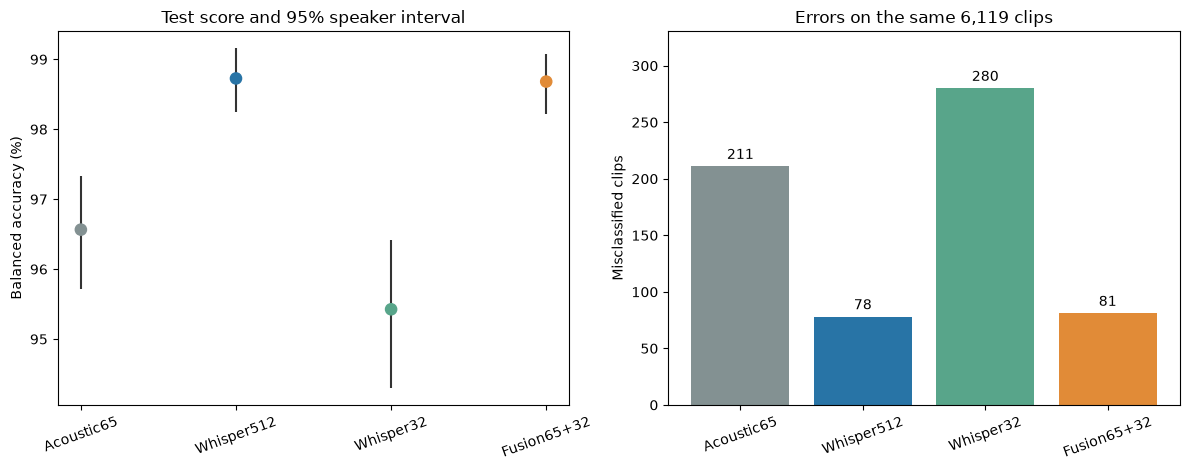

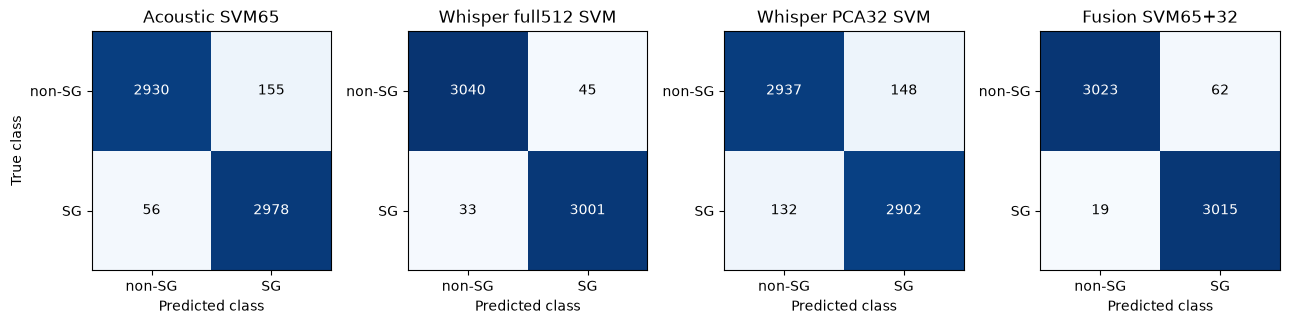

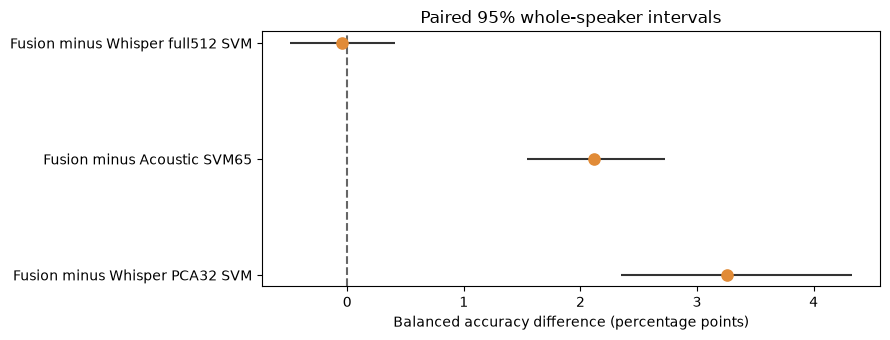

In [9]:
test_scores, score_details, paired = paired_bootstrap(test_predictions, NAMES)
test_scores['C'] = test_scores.model.map(selected_c)
test_scores.to_csv(OUT / 'test_scores.csv', index=False)
subgroups = source_table(test_predictions)
display(test_scores[['model', 'C', 'balanced_accuracy', 'ba_ci95_low', 'ba_ci95_high',
                     'macro_f1', 'roc_auc', 'false_positive', 'false_negative', 'errors']])
paired_display = paired.assign(difference_pp=100*paired.difference,
                                low_pp=100*paired.ci95_low, high_pp=100*paired.ci95_high)
display(paired_display[['reference', 'metric', 'difference_pp', 'low_pp', 'high_pp',
                        'fusion_only_correct', 'reference_only_correct']])
display(subgroups)
for row in paired.loc[paired.metric.eq('balanced_accuracy')].itertuples(index=False):
    print(describe_difference(row))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
values = test_scores.balanced_accuracy.to_numpy()*100
x = np.arange(len(NAMES))
low, high = test_scores.ba_ci95_low.to_numpy()*100, test_scores.ba_ci95_high.to_numpy()*100
axes[0].vlines(x, low, high, color='#333333', linewidth=1.5)
axes[0].scatter(x, values, color=['#839192', '#2874a6', '#58a58a', '#e18b37'], s=65, zorder=3)
axes[0].set(xticks=x, xticklabels=['Acoustic65', 'Whisper512', 'Whisper32', 'Fusion65+32'],
            ylabel='Balanced accuracy (%)', title='Test score and 95% speaker interval')
axes[0].tick_params(axis='x', rotation=20)
bars = axes[1].bar(x, test_scores.errors, color=['#839192', '#2874a6', '#58a58a', '#e18b37'])
axes[1].bar_label(bars, padding=3)
axes[1].set(xticks=x, xticklabels=['Acoustic65', 'Whisper512', 'Whisper32', 'Fusion65+32'],
            ylabel='Misclassified clips', title='Errors on the same 6,119 clips')
axes[1].set_ylim(0, max(test_scores.errors)*1.18)
axes[1].tick_params(axis='x', rotation=20)
fig.tight_layout()
plt.show()
plt.close(fig)

fig, axes = plt.subplots(1, 4, figsize=(13, 3.5))
for ax, name in zip(axes, NAMES):
    cm = np.asarray(score_details[name]['confusion_matrix'])
    ax.imshow(cm, cmap='Blues', vmin=0, vmax=3100)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, str(cm[i, j]), ha='center', va='center',
                    color='white' if cm[i, j] > 1550 else 'black')
    ax.set(xticks=[0, 1], yticks=[0, 1], xticklabels=['non-SG', 'SG'],
           yticklabels=['non-SG', 'SG'], xlabel='Predicted class', title=name)
axes[0].set_ylabel('True class')
fig.tight_layout()
plt.show()
plt.close(fig)

ba_pairs = paired.loc[paired.metric.eq('balanced_accuracy')].reset_index(drop=True)
fig, ax = plt.subplots(figsize=(9, 3.5))
positions = np.arange(len(ba_pairs))
ax.hlines(positions, 100*ba_pairs.ci95_low, 100*ba_pairs.ci95_high, color='#333333')
ax.scatter(100*ba_pairs.difference, positions, color='#e18b37', s=65, zorder=3)
ax.axvline(0, color='#666666', linestyle='--')
ax.set(yticks=positions, yticklabels=['Fusion minus '+name for name in ba_pairs.reference],
       xlabel='Balanced accuracy difference (percentage points)',
       title='Paired 95% whole-speaker intervals')
ax.invert_yaxis()
fig.tight_layout()
plt.show()
plt.close(fig)

## 9. Inspect source errors and save the report

All Singapore-positive clips come from MNSC. The negative clips come from Common Voice, SAA, and SpeechOcean. Source and class are confounded. A source score cannot separate accent cues from corpus or recording cues. Do not call these results proof of broad accent generalization.

The table below shows the largest absolute decision scores among each model's errors. Use these examples for later audio review. A large absolute score is a large SVM margin, not a calibrated probability. These examples do not change the current model.

Six files are kept in the new output folder: one model/checkpoint file, three CSV files, one Markdown report, and one JSON run record. Plots stay in this notebook. Save the notebook after the run to retain its plots and displayed tables. This run does not create a completed central archive automatically.

In [10]:
errors = test_predictions.loc[test_predictions.label.ne(test_predictions.prediction)].copy()
errors['absolute_margin'] = errors.decision_score.abs()
error_examples = (errors.sort_values('absolute_margin', ascending=False)
                 .groupby('model', sort=False).head(5))
display(error_examples[['model', 'clip_id', 'speaker_group', 'source', 'label',
                        'prediction', 'decision_score']])

display_scores = test_scores[['model', 'C', 'balanced_accuracy', 'macro_f1',
                              'roc_auc', 'false_positive', 'false_negative', 'errors']].copy()
display_scores['balanced_accuracy'] = display_scores.balanced_accuracy.map(lambda x: f'{100*x:.2f}%')
for column in ['macro_f1', 'roc_auc']:
    display_scores[column] = display_scores[column].map(lambda x: f'{x:.4f}')
display_paired = paired_display[['reference', 'metric', 'difference_pp', 'low_pp', 'high_pp']].copy()
for column in ['difference_pp', 'low_pp', 'high_pp']:
    display_paired[column] = display_paired[column].map(lambda x: f'{x:+.3f}')
source_display = subgroups.copy()
source_display['value'] = source_display.value.map(lambda x: f'{100*x:.2f}%')
selected_validation = validation_trials.loc[validation_trials.selected,
    ['model', 'C', 'balanced_accuracy', 'macro_f1', 'origin']].copy()
conclusions = [describe_difference(row) for row in ba_pairs.itertuples(index=False)]
rank = state['ranking']
lines = [
    '# A1: matched acoustic, frozen Whisper, and fusion comparison', '',
    'Status: complete. This is a retrospective comparison on an already inspected test set.', '',
    '## Procedure', '',
    'Data: final 24 October preparation, 40,000 clips. Train 27,797; validation 6,084; development 33,881; test 6,119. Speaker overlap across train, validation, and test: zero.', '',
    'Whisper: frozen openai/whisper-base.en, revision '+fw.REVISION+'. Reuse the verified final feature cache and completed E2 controls. No new extraction or Whisper head training.', '',
    'Rank all 91 acoustic inputs using a C=1 full91 SVM on original training speakers only. Permutation importance: balanced accuracy, five repeats, seed 42. Select 65 inputs, then keep those columns fixed. Do not use historical development-ranked columns.', '',
    'Tune acoustic SVM65 and fusion over C=0.01, 0.1, 1, 10. Select validation BA, then macro F1, then smaller C. Match the completed Whisper control search. Fit scaling and PCA within each fitting partition.', '',
    'Fusion: standardize acoustic65 and divide by sqrt(65); standardize Whisper512, reduce to PCA32, standardize components, and divide by sqrt(32). Concatenate to 97 processed inputs and fit one RBF SVM. Refit both selected pipelines on development data. No probability calibration.', '',
    '## Selected validation results', '', markdown_table(selected_validation), '',
    '## Test results', '', markdown_table(display_scores), '',
    '## Paired differences', '',
    'Values below are percentage-point differences. Use 2,000 paired whole-speaker bootstrap draws, stratified by class, seed 42. Primary: fusion minus full512 Whisper. Secondary comparisons are descriptive. No multiple-comparison correction.', '',
    markdown_table(display_paired), '', *conclusions, '',
    '## Source scores', '', markdown_table(source_display), '',
    'All Singapore positives are MNSC. Source and class are confounded. These scores do not isolate accent from recording or corpus cues.', '',
    '## Time', '',
    f'Ranking-model fit: {rank["fit_seconds"]:.1f} s. Permutation ranking: {rank["permutation_seconds"]:.1f} s. These are one-time selection costs.', '',
    markdown_table(timing), '',
    'Fit and prediction times use cached features. Prediction time includes separate predict and decision-score calls. E2 times come from a separate completed run. These times are descriptive, not an end-to-end deployment benchmark.', '',
    '## Limits', '',
    'The test set was inspected in earlier work. Count65, PCA32, branch weights, and the model family are prior project choices. Training-set permutation importance is not an independent feature-importance test. Correlated inputs can share importance. Reduced input count alone does not prove less overfitting. Bootstrap intervals condition on fixed fitted models and do not include training or selection uncertainty. An interval containing zero does not establish equivalence. Development speaker folds were not repeated here.', '',
    '## Error examples for audio review', '',
    'Up to five errors per model, ordered by absolute SVM margin. Decision scores are not probabilities.', '',
    markdown_table(error_examples[['model', 'clip_id', 'source', 'label', 'prediction', 'decision_score']]), '',
    '## Files', '',
    '- study.joblib: training-only ranking, selected columns, C trials, and fitted acoustic/fusion pipelines.',
    '- validation_trials.csv: all four C values for all four models; selected rows are marked.',
    '- predictions.csv: validation and test predictions for all four models, with IDs, speakers, labels, sources, and decision scores.',
    '- test_scores.csv: test metrics and speaker intervals.',
    '- run_record.json: settings, input hashes, audio audit, full ranking, selected C, metrics, paired differences, source scores, and time.',
    '- report.md: this report.', '',
    'Save the executed notebook to retain the charts. Add the completed study to the central final-test archive after review.', '',
]
(OUT / 'report.md').write_text('\n'.join(lines))
record.update(status='complete', completed_utc=datetime.now(timezone.utc).isoformat(),
              selected_C=selected_c, acoustic_ranking=ranking_table.to_dict('records'),
              ranking_fit_seconds=rank['fit_seconds'], ranking_permutation_seconds=rank['permutation_seconds'],
              selected_columns=selected_columns.tolist(), selected_feature_names=state['selected_feature_names'],
              test_metrics=score_details, paired_differences=paired.to_dict('records'),
              source_scores=subgroups.to_dict('records'), timing=timing.to_dict('records'),
              test_clips=len(test), test_speakers=frame.iloc[test].speaker_group.nunique(),
              primary_comparison='Fusion SVM65+32 minus Whisper full512 SVM',
              interval_scope='fixed fitted models; excludes training and selection uncertainty',
              generated_files={name: sha256(OUT/name) for name in
                               ['study.joblib', 'validation_trials.csv', 'predictions.csv', 'test_scores.csv', 'report.md']})
fw.write_json(OUT / 'run_record.json', record)
assert len(list(OUT.iterdir())) == 6
display(Markdown('**Study complete.** Report: `'+str(OUT / 'report.md')+'`'))
print('Save this executed notebook to retain its results and charts.')

,model,clip_id,speaker_group,source,label,prediction,decision_score
12158,Whisper PCA32 SVM,speechocean762::so762_012930040,speechocean762::so762_1293,speechocean762,0,1,3.264584
12168,Whisper PCA32 SVM,speechocean762::so762_013720189,speechocean762::so762_1372,speechocean762,0,1,3.239443
9512,Whisper PCA32 SVM,mnsc::mnsc_part1-train_00002_01341,mnsc::mnsc_07000000,mnsc,1,0,-3.160819
9993,Whisper PCA32 SVM,mnsc::mnsc_part1-train_00194_00628,mnsc::mnsc_07000000,mnsc,1,0,-2.632422
18211,Acoustic SVM65,speech_accent_archive::saa_korean1_c04,speech_accent_archive::saa_korean1,speech_accent_archive,0,1,2.562160
12162,Whisper PCA32 SVM,speechocean762::so762_012930225,speechocean762::so762_1293,speechocean762,0,1,2.489282
18214,Acoustic SVM65,speech_accent_archive::saa_korean1_c07,speech_accent_archive::saa_korean1,speech_accent_archive,0,1,2.190130
18212,Acoustic SVM65,speech_accent_archive::saa_korean1_c05,speech_accent_archive::saa_korean1,speech_accent_archive,0,1,2.032984
14250,Acoustic SVM65,common_voice::common_voice_en_26958478,common_voice::540f0011f2a723d6be242cd3fe47f450...,common_voice,0,1,1.986972
18209,Acoustic SVM65,speech_accent_archive::saa_korean1_c02,speech_accent_archive::saa_korean1,speech_accent_archive,0,1,1.897115


**Study complete.** Report: `/home/mh/nusproj/singlish-whisper/outputs/a1_tuned_acoustic_whisper_fusion_40000/report.md`

Save this executed notebook to retain its results and charts.


## 10. Use the result in the project report

- Report the primary fusion-minus-full512 difference and its interval, even if fusion does not improve.
- State the fusion gain over acoustic SVM65 separately. Use the values from this rerun.
- Report FP and FN. A similar balanced accuracy can hide a different error trade-off.
- State that Whisper stays frozen. Describe the fusion as feature concatenation followed by one SVM.
- Keep the retrospective-test and source-confounding limits.
- Do not tune a new model after reading these test results and then describe the same test as independent confirmation.

This completes the planned A1 train/validation/test comparison if all cells pass. New external data, probability calibration, deployment timing, and another development speaker-fold study are separate tasks.